In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

In [ ]:

df1 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')



📊 THỐNG KÊ SỐ LƯỢNG NHÃN TRÊN TẬP df1 (Tổng: 323 mẫu)
    Nhãn mức độ  Số lượng mẫu  Tỷ lệ (%)
      L0 (Thấp)           117      36.22
L1 (Trung bình)           189      58.51
       L2 (Cao)            17       5.26


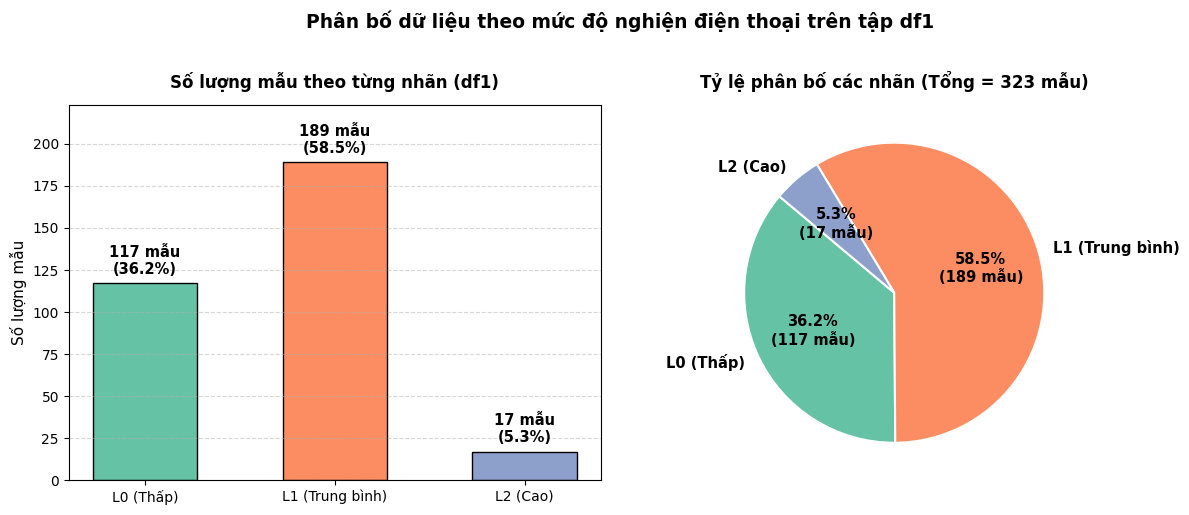

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# 1. ĐỌC DỮ LIỆU df1 & CHUẨN HÓA CỘT NHÃN 'Level'
# =========================================================================
df1 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
Y = df1['Level'].copy()

if Y.dtype == 'object' or Y.dtype.name == 'category':
    Y = Y.astype(str).str.strip().map({'L0': 0, 'L1': 1, 'L2': 2, '0': 0, '1': 1, '2': 2})
Y = pd.to_numeric(Y, errors='coerce').dropna().astype(int)
if len(Y) > 0 and Y.min() == 1:
    Y = Y - 1

# =========================================================================
# 2. THỐNG KÊ & IN SỐ LƯỢNG L0, L1, L2 TRÊN df1
# =========================================================================
label_names = ['L0 (Thấp)', 'L1 (Trung bình)', 'L2 (Cao)']
counts = [int((Y == i).sum()) for i in [0, 1, 2]]
total = sum(counts)
percentages = [(c / total * 100) if total > 0 else 0 for c in counts]

df_dist = pd.DataFrame({
    'Nhãn mức độ': label_names,
    'Số lượng mẫu': counts,
    'Tỷ lệ (%)': [round(p, 2) for p in percentages]
})

print("=" * 52)
print(f"📊 THỐNG KÊ SỐ LƯỢNG NHÃN TRÊN TẬP df1 (Tổng: {total} mẫu)")
print("=" * 52)
print(df_dist.to_string(index=False))
print("=" * 52)

# =========================================================================
# 3. VẼ BIỂU ĐỒ PHÂN BỐ SỐ LƯỢNG & TỶ LỆ L0, L1, L2
# =========================================================================
colors = ['#66c2a5', '#fc8d62', '#8da0cb']
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))

# Biểu đồ cột (số lượng + phần trăm)
bars = axes[0].bar(label_names, counts, color=colors, edgecolor='black', width=0.55)
for bar, count, pct in zip(bars, counts, percentages):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(counts) * 0.02,
        f"{count} mẫu\n({pct:.1f}%)",
        ha='center', va='bottom', fontsize=10.5, fontweight='bold'
    )
axes[0].set_title('Số lượng mẫu theo từng nhãn (df1)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel('Số lượng mẫu', fontsize=11)
axes[0].set_ylim(0, max(counts) * 1.18)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Biểu đồ tròn (tỷ lệ phần trăm)
axes[1].pie(
    counts,
    labels=label_names,
    autopct=lambda p: f'{p:.1f}%\n({int(round(p * total / 100))} mẫu)',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10.5, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
axes[1].set_title(f'Tỷ lệ phân bố các nhãn (Tổng = {total} mẫu)', fontsize=12, fontweight='bold', pad=12)

plt.suptitle('Phân bố dữ liệu theo mức độ nghiện điện thoại trên tập df1', fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Phan_bo_L0_L1_L2_df1.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
df1 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')

cols = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
X = df1[[c for c in cols if c in df1.columns]].apply(pd.to_numeric, errors='coerce')
Y = df1['Level'].replace({'L0': 0, 'L1': 1, 'L2': 2})
Y = pd.to_numeric(Y, errors='coerce')

# Lọc dòng hợp lệ, điền ô trống bằng median và tạo 3 đặc trưng tổng hợp
valid = Y.notna()
X, Y = X[valid].fillna(X[valid].median()).fillna(0), Y[valid].astype(int)

q_cols = [c for c in cols[1:] if c in X.columns]
X['Q_mean'] = X[q_cols].mean(axis=1)
X['Q_std']  = X[q_cols].std(axis=1)
X['Q_max']  = X[q_cols].max(axis=1)
# 1. Chia dữ liệu: 70% Train - 15% Validation - 15% Test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, Y,
    test_size=0.15,
    random_state=42,
    stratify=Y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=(15 / 85),
    random_state=42,
    stratify=y_temp
)

# 2. Chuẩn hóa & SMOTE trên tập Train (sẵn sàng cho mô hình học ở bước sau)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

sm = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

# 3. Đếm số lượng mẫu, tỷ lệ % và phân bố từng lớp
tong = len(Y)
def dem_lop(y):
    return dict(pd.Series(y).value_counts().sort_index())

print(f"Tổng dữ liệu:     {tong} mẫu (100.0%) | Phân bố: {dem_lop(Y)}")
print(f"Train gốc:        {len(y_train)} mẫu ({len(y_train)/tong*100:.1f}%) | Phân bố: {dem_lop(y_train)}")
print(f"Train sau SMOTE:  {len(y_train_res)} mẫu          | Phân bố: {dem_lop(y_train_res)}")
print(f"Validation:       {len(y_val)} mẫu ({len(y_val)/tong*100:.1f}%)  | Phân bố: {dem_lop(y_val)}")
print(f"Test:             {len(y_test)} mẫu ({len(y_test)/tong*100:.1f}%)  | Phân bố: {dem_lop(y_test)}")

Tổng dữ liệu:     323 mẫu (100.0%) | Phân bố: {0: np.int64(117), 1: np.int64(189), 2: np.int64(17)}
Train gốc:        225 mẫu (69.7%) | Phân bố: {0: np.int64(81), 1: np.int64(132), 2: np.int64(12)}
Train sau SMOTE:  396 mẫu          | Phân bố: {0: np.int64(132), 1: np.int64(132), 2: np.int64(132)}
Validation:       49 mẫu (15.2%)  | Phân bố: {0: np.int64(18), 1: np.int64(28), 2: np.int64(3)}
Test:             49 mẫu (15.2%)  | Phân bố: {0: np.int64(18), 1: np.int64(29), 2: np.int64(2)}


In [ ]:
import pandas as pd
import numpy as np

# Kiểm tra xem Cell 1 đã chạy chưa; nếu chưa thì báo rõ để chạy Cell 1 trước
required_vars = ['y_train', 'y_val', 'y_test', 'y_train_res']
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise RuntimeError(f"⚠️ Bạn chưa chạy Cell 1! Hãy bấm chạy Cell 1 phía trên trước để tạo các biến: {missing_vars}")

# ==========================================
# 6. THỐNG KÊ SỐ LƯỢNG & TỶ LỆ L0, L1, L2 TRÊN TỪNG TẬP (70/15/15)
# ==========================================
def thong_ke_phan_bo(splits_dict):
    all_y = np.concatenate([np.asarray(y) for y in splits_dict.values()])
    unique_classes = sorted(np.unique(all_y))

    # Lấy tên nhãn chuẩn ('L0', 'L1', 'L2')
    if 'le' in globals() and hasattr(le, 'classes_') and len(le.classes_) == len(unique_classes):
        label_names = list(le.classes_)
    else:
        label_names = [f"L{int(c)}" for c in unique_classes]

    rows = []
    for name, y_data in splits_dict.items():
        y_arr = np.asarray(y_data)
        total = len(y_arr)
        row = {
            'Tập dữ liệu': name,
            'Tổng mẫu': total
        }
        for cls_val, lbl in zip(unique_classes, label_names):
            count = int(np.sum(y_arr == cls_val))
            pct = (count / total * 100) if total > 0 else 0.0
            row[f'{lbl} (Số lượng / Tỷ lệ)'] = f"{count} ({pct:.2f}%)"
        rows.append(row)

    return pd.DataFrame(rows)

df_phan_bo = thong_ke_phan_bo({
    'Tập Train gốc (70%)': y_train,
    'Tập Validation (15%)': y_val,
    'Tập Test (15%)': y_test,
    'Tập Train sau SMOTE': y_train_res
})

print("=" * 95)
print("📊 THỐNG KÊ SỐ LƯỢNG VÀ TỶ LỆ NHÃN L0, L1, L2 THEO TỶ LỆ CHIA 70/15/15")
print("=" * 95)
print(df_phan_bo.to_string(index=False))
print("=" * 95)

📊 THỐNG KÊ SỐ LƯỢNG VÀ TỶ LỆ NHÃN L0, L1, L2 THEO TỶ LỆ CHIA 70/15/15
         Tập dữ liệu  Tổng mẫu L0 (Số lượng / Tỷ lệ) L1 (Số lượng / Tỷ lệ) L2 (Số lượng / Tỷ lệ)
 Tập Train gốc (70%)       225           81 (36.00%)          132 (58.67%)            12 (5.33%)
Tập Validation (15%)        49           18 (36.73%)           28 (57.14%)             3 (6.12%)
      Tập Test (15%)        49           18 (36.73%)           29 (59.18%)             2 (4.08%)
 Tập Train sau SMOTE       396          132 (33.33%)          132 (33.33%)          132 (33.33%)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from tensorflow.keras.utils import to_categorical

# =========================================================================
# BƯỚC 1: ĐỌC DỮ LIỆU MỚI & LÀM SẠCH NHÃN / ĐẶC TRƯNG CƠ BẢN
# =========================================================================
df1 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df1.columns]

X = df1[valid_features].copy()
Y = df1['Level'].copy()

# Chuẩn hóa nhãn Y về dạng số nguyên 0, 1, 2
if Y.dtype == 'object':
    Y = Y.astype(str).str.strip().map({'L0': 0, 'L1': 1, 'L2': 2, '0': 0, '1': 1, '2': 2})
Y = pd.to_numeric(Y, errors='coerce')

# Loại bỏ dòng thiếu nhãn Level và ép kiểu số cho các cột đặc trưng
valid_idx = Y.notna()
X = X[valid_idx].apply(pd.to_numeric, errors='coerce')
Y = Y[valid_idx].astype(int)

# Feature Engineering (tính theo từng dòng nên không gây rò rỉ dữ liệu)
q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X.columns]
if len(q_cols) > 0:
    X['Q_mean'] = X[q_cols].mean(axis=1)  # Điểm trung bình các câu hỏi
    X['Q_std']  = X[q_cols].std(axis=1)   # Độ phân tán câu trả lời
    X['Q_max']  = X[q_cols].max(axis=1)   # Mức điểm cao nhất

# =========================================================================
# BƯỚC 2: CHIA TẬP CHUẨN TỶ LỆ 70% TRAIN - 15% VALIDATION - 15% TEST
# =========================================================================
X_temp, X_test, y_temp, y_test = train_test_split(
    X, Y,
    test_size=0.15,
    random_state=42,
    stratify=Y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=(15 / 85),
    random_state=42,
    stratify=y_temp
)

# =========================================================================
# BƯỚC 3: XỬ LÝ GIÁ TRỊ KHUYẾT (NaN) & NGOẠI LAI (OUTLIERS) THEO TẬP TRAIN
# =========================================================================
# 3a. Điền khuyết bằng trung vị (Median) học từ tập Train
train_medians = X_train.median()
X_train = X_train.fillna(train_medians).fillna(0)
X_val   = X_val.fillna(train_medians).fillna(0)
X_test  = X_test.fillna(train_medians).fillna(0)

# 3b. Cắt ngoại lai (IQR Capping) cho biến thời gian sử dụng điện thoại
if 'tg_sudung_dt' in X_train.columns:
    Q1 = X_train['tg_sudung_dt'].quantile(0.25)
    Q3 = X_train['tg_sudung_dt'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    X_train['tg_sudung_dt'] = np.clip(X_train['tg_sudung_dt'], lower_bound, upper_bound)
    X_val['tg_sudung_dt']   = np.clip(X_val['tg_sudung_dt'], lower_bound, upper_bound)
    X_test['tg_sudung_dt']  = np.clip(X_test['tg_sudung_dt'], lower_bound, upper_bound)

# =========================================================================
# BƯỚC 4: CHUẨN HÓA DỮ LIỆU (STANDARDSCALER) TRÊN DỮ LIỆU THẬT
# =========================================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Chỉ fit trên Train
X_val_scaled   = scaler.transform(X_val)        # Áp dụng sang Validation
X_test_scaled  = scaler.transform(X_test)       # Áp dụng sang Test

# =========================================================================
# BƯỚC 5: CÂN BẰNG LỚP BẰNG SMOTE (CHỈ ÁP DỤNG TRÊN TẬP TRAIN)
# =========================================================================
sm = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

# Chuyển nhãn sang One-Hot Encoding phục vụ mạng FNN
num_classes = len(np.unique(Y))
y_train_oh = to_categorical(y_train_res, num_classes=num_classes)
y_val_oh   = to_categorical(y_val, num_classes=num_classes)
y_test_oh  = to_categorical(y_test, num_classes=num_classes)

# =========================================================================
# BƯỚC 6: KIỂM TRA KẾT QUẢ XỬ LÝ & CHUẨN HÓA
# =========================================================================
tong = len(Y)
def dem_lop(y):
    return dict(pd.Series(y).value_counts().sort_index())

print("=" * 75)
print("✅ HOÀN TẤT XỬ LÝ & CHUẨN HÓA DỮ LIỆU MỚI (data2.csv)")
print("=" * 75)
print(f"• Số đặc trưng đầu vào: {X_train_res.shape[1]} cột -> {list(X_train.columns)}")
print(f"• Tổng dữ liệu sạch:    {tong} mẫu (100.0%) | Phân bố: {dem_lop(Y)}")
print(f"• Train gốc:           {len(y_train)} mẫu ({len(y_train)/tong*100:.1f}%)  | Phân bố: {dem_lop(y_train)}")
print(f"• Train sau SMOTE:     {len(y_train_res)} mẫu          | Phân bố: {dem_lop(y_train_res)}")
print(f"• Validation (gốc):    {len(y_val)} mẫu ({len(y_val)/tong*100:.1f}%)   | Phân bố: {dem_lop(y_val)}")
print(f"• Test độc lập (gốc):  {len(y_test)} mẫu ({len(y_test)/tong*100:.1f}%)   | Phân bố: {dem_lop(y_test)}")
print(f"• Kiểm tra chuẩn hóa Train: Mean ≈ {X_train_scaled.mean():.4f}, Std ≈ {X_train_scaled.std():.4f}")
print("=" * 75)

✅ HOÀN TẤT XỬ LÝ & CHUẨN HÓA DỮ LIỆU MỚI (data2.csv)
• Số đặc trưng đầu vào: 14 cột -> ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Q_mean', 'Q_std', 'Q_max']
• Tổng dữ liệu sạch:    323 mẫu (100.0%) | Phân bố: {0: np.int64(117), 1: np.int64(189), 2: np.int64(17)}
• Train gốc:           225 mẫu (69.7%)  | Phân bố: {0: np.int64(81), 1: np.int64(132), 2: np.int64(12)}
• Train sau SMOTE:     396 mẫu          | Phân bố: {0: np.int64(132), 1: np.int64(132), 2: np.int64(132)}
• Validation (gốc):    49 mẫu (15.2%)   | Phân bố: {0: np.int64(18), 1: np.int64(28), 2: np.int64(3)}
• Test độc lập (gốc):  49 mẫu (15.2%)   | Phân bố: {0: np.int64(18), 1: np.int64(29), 2: np.int64(2)}
• Kiểm tra chuẩn hóa Train: Mean ≈ 0.0000, Std ≈ 1.0000


🚀 Bắt đầu huấn luyện 10-Fold Optimized Ensemble FNN trên data2.csv (323 mẫu)...
✅ Hoàn tất Fold  1/10 | Val Accuracy: 92.86%
✅ Hoàn tất Fold  2/10 | Val Accuracy: 96.43%


✅ Hoàn tất Fold  3/10 | Val Accuracy: 96.43%
✅ Hoàn tất Fold  4/10 | Val Accuracy: 92.86%
✅ Hoàn tất Fold  5/10 | Val Accuracy: 100.00%
✅ Hoàn tất Fold  6/10 | Val Accuracy: 100.00%
✅ Hoàn tất Fold  7/10 | Val Accuracy: 100.00%
✅ Hoàn tất Fold  8/10 | Val Accuracy: 88.89%
✅ Hoàn tất Fold  9/10 | Val Accuracy: 96.30%
✅ Hoàn tất Fold 10/10 | Val Accuracy: 100.00%

--- KẾT QUẢ 10-FOLD OPTIMIZED ENSEMBLE FNN (DATA MỚI) ---
📊 Độ chính xác trung bình trên 10-Fold Validation (OOF): 96.35%
🎯 Độ chính xác (Accuracy) trên tập Test độc lập (15%):  95.92%

--- BÁO CÁO CHI TIẾT TỪNG NHÓM (PRECISION / RECALL / F1-SCORE) ---
                 precision    recall  f1-score   support

      L0 (Thấp)     1.0000    0.9444    0.9714        18
L1 (Trung bình)     0.9655    0.9655    0.9655        29
       L2 (Cao)     0.6667    1.0000    0.8000         2

       accuracy                         0.9592        49
      macro avg     0.8774    0.9700    0.9123        49
   weighted avg     0.9660    0.9592  

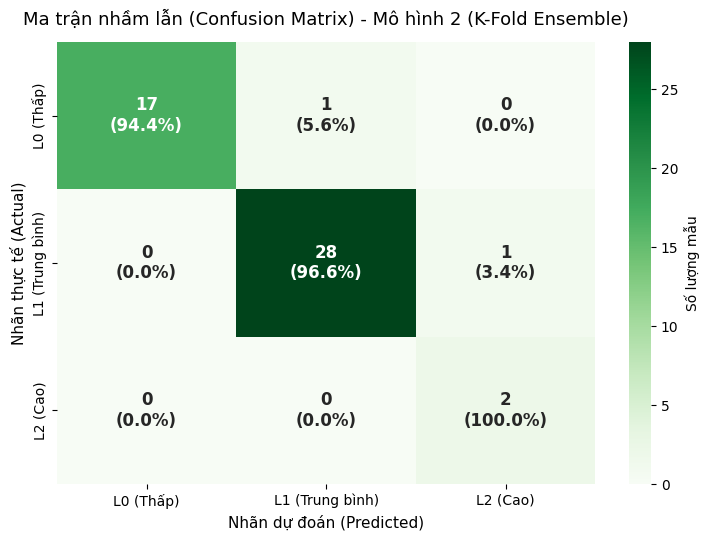

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================================
# 1. ĐỌC DỮ LIỆU MỚI (data2.csv) & FEATURE ENGINEERING
# =========================================================================
df1 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df1.columns]

X_original = df1[valid_features].copy()
Y = df1['Level'].copy()

# Chuẩn hóa nhãn Y an toàn (xử lý cả dạng chuỗi có khoảng trắng hoặc số)
if Y.dtype == 'object':
    Y = Y.astype(str).str.strip().map({'L0': 0, 'L1': 1, 'L2': 2, '0': 0, '1': 1, '2': 2})
Y = pd.to_numeric(Y, errors='coerce')

valid_idx = Y.notna()
X_original = X_original[valid_idx].apply(pd.to_numeric, errors='coerce')
Y = Y[valid_idx].astype(int)

# Tạo đặc trưng tổng hợp từ nhóm câu hỏi Q1 - Q10
q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X_original.columns]
if len(q_cols) > 0:
    X_original['Q_mean'] = X_original[q_cols].mean(axis=1)  # Trung bình điểm các câu hỏi
    X_original['Q_std']  = X_original[q_cols].std(axis=1)   # Độ lệch chuẩn giữa các câu
    X_original['Q_max']  = X_original[q_cols].max(axis=1)   # Mức độ nghiêm trọng cao nhất

# =========================================================================
# 2. TÁCH TẬP TEST ĐỘC LẬP (15% - KHỚP HOÀN TOÀN VỚI CHIA 70/15/15)
# =========================================================================
X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.15, random_state=42, stratify=Y
)

# =========================================================================
# 3. KIẾN TRÚC MẠNG FNN TỐI ƯU (MISH + BATCHNORM + DROPOUT)
# =========================================================================
def create_optimized_fnn(input_dim, output_classes):
    model = Sequential([
        Input(shape=(input_dim,)),

        Dense(128, activation='mish'),
        BatchNormalization(),
        Dropout(0.2),

        Dense(64, activation='mish'),
        BatchNormalization(),
        Dropout(0.15),

        Dense(32, activation='mish'),
        BatchNormalization(),
        Dropout(0.1),

        Dense(output_classes, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# =========================================================================
# 4. HUẤN LUYỆN 10-FOLD ENSEMBLE FNN TRÊN TẬP DỮ LIỆU MỚI
# =========================================================================
n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

output_classes = len(np.unique(Y))
test_predictions_folds = np.zeros((len(X_test_raw), output_classes))
oof_predictions = np.zeros((len(X_train_raw), output_classes))

print(f"🚀 Bắt đầu huấn luyện {n_splits}-Fold Optimized Ensemble FNN trên data2.csv ({len(Y)} mẫu)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_raw, Y_train_raw), 1):
    tf.keras.backend.clear_session()
    tf.random.set_seed(42 + fold)

    X_tr = X_train_raw.iloc[train_idx].copy()
    Y_tr = Y_train_raw.iloc[train_idx].copy()

    X_val = X_train_raw.iloc[val_idx].copy()
    Y_val = Y_train_raw.iloc[val_idx].copy()

    X_te = X_test_raw.copy()

    # Bước A: Điền giá trị khuyết (NaN) bằng median của tập Train Fold (+ dự phòng 0)
    fold_medians = X_tr.median()
    X_tr = X_tr.fillna(fold_medians).fillna(0)
    X_val = X_val.fillna(fold_medians).fillna(0)
    X_te = X_te.fillna(fold_medians).fillna(0)

    # Bước B: Xử lý ngoại lai (Outlier Capping) theo ngưỡng IQR của tập Train
    feature_outlier = 'tg_sudung_dt'
    if feature_outlier in X_tr.columns:
        Q1 = X_tr[feature_outlier].quantile(0.25)
        Q3 = X_tr[feature_outlier].quantile(0.75)
        IQR = Q3 - Q1
        upper_bound = Q3 + 1.5 * IQR
        lower_bound = Q1 - 1.5 * IQR

        X_tr[feature_outlier] = np.clip(X_tr[feature_outlier], lower_bound, upper_bound)
        X_val[feature_outlier] = np.clip(X_val[feature_outlier], lower_bound, upper_bound)
        X_te[feature_outlier] = np.clip(X_te[feature_outlier], lower_bound, upper_bound)

    # Bước C: Chuẩn hóa StandardScaler trên dữ liệu thật TRƯỚC khi SMOTE
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_val_scaled = scaler.transform(X_val)
    X_te_scaled = scaler.transform(X_te)

    # Bước D: Cân bằng lớp bằng SMOTE trên không gian đã chuẩn hóa
    sm = SMOTE(sampling_strategy='auto', random_state=42 + fold)
    X_tr_res, Y_tr_res = sm.fit_resample(X_tr_scaled, Y_tr)

    # Bước E: One-Hot Encoding
    Y_tr_one_hot = to_categorical(Y_tr_res, num_classes=output_classes)
    Y_val_one_hot = to_categorical(Y_val, num_classes=output_classes)

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-5, verbose=0)
    ]

    model = create_optimized_fnn(input_dim=X_tr_res.shape[1], output_classes=output_classes)

    model.fit(
        X_tr_res, Y_tr_one_hot,
        epochs=200,
        batch_size=16,
        validation_data=(X_val_scaled, Y_val_one_hot),
        callbacks=callbacks,
        verbose=0
    )

    val_pred_prob = model.predict(X_val_scaled, verbose=0)
    oof_predictions[val_idx] = val_pred_prob
    val_acc = accuracy_score(Y_val, np.argmax(val_pred_prob, axis=1))

    fold_test_pred_prob = model.predict(X_te_scaled, verbose=0)
    test_predictions_folds += fold_test_pred_prob / n_splits

    print(f"✅ Hoàn tất Fold {fold:2d}/{n_splits} | Val Accuracy: {val_acc * 100:.2f}%")

# =========================================================================
# 5. TỔNG HỢP VÀ ĐÁNH GIÁ KẾT QUẢ
# =========================================================================
oof_accuracy = accuracy_score(Y_train_raw, np.argmax(oof_predictions, axis=1))

Y_pred_class = np.argmax(test_predictions_folds, axis=1)
Y_test_class = Y_test_raw.values

cm_count = confusion_matrix(Y_test_class, Y_pred_class)
cm_sum = cm_count.sum(axis=1)[:, np.newaxis]
cm_percent = np.divide(cm_count, cm_sum, out=np.zeros_like(cm_count, dtype=float), where=cm_sum != 0) * 100

test_accuracy = accuracy_score(Y_test_class, Y_pred_class)

print("\n" + "=" * 60)
print("--- KẾT QUẢ 10-FOLD OPTIMIZED ENSEMBLE FNN (DATA MỚI) ---")
print("=" * 60)
print(f"📊 Độ chính xác trung bình trên 10-Fold Validation (OOF): {oof_accuracy * 100:.2f}%")
print(f"🎯 Độ chính xác (Accuracy) trên tập Test độc lập (15%):  {test_accuracy * 100:.2f}%")

print("\n--- BÁO CÁO CHI TIẾT TỪNG NHÓM (PRECISION / RECALL / F1-SCORE) ---")
print(classification_report(
    Y_test_class,
    Y_pred_class,
    target_names=['L0 (Thấp)', 'L1 (Trung bình)', 'L2 (Cao)'],
    digits=4
))

print("--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count = pd.DataFrame(
    cm_count,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count)

print("\n--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent = pd.DataFrame(
    cm_percent,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent.astype(str) + '%')
print("=" * 60)

# Vẽ biểu đồ Heatmap
annot_labels = np.empty_like(cm_count, dtype=object)
for i in range(cm_count.shape[0]):
    for j in range(cm_count.shape[1]):
        annot_labels[i, j] = f"{cm_count[i, j]}\n({cm_percent[i, j]:.1f}%)"

labels = ['L0 (Thấp)', 'L1 (Trung bình)', 'L2 (Cao)']

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(
    cm_count,
    annot=annot_labels,
    fmt='',
    cmap='Greens',
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={"size": 12, "weight": "bold"},
    cbar_kws={'label': 'Số lượng mẫu'}
)
plt.title('Ma trận nhầm lẫn (Confusion Matrix) - Mô hình 2 (K-Fold Ensemble)', fontsize=13, pad=12)
plt.xlabel('Nhãn dự đoán (Predicted)', fontsize=11)
plt.ylabel('Nhãn thực tế (Actual)', fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display
from google.colab import files

# Cấu hình hiển thị toàn bộ cột (không bị thu gọn thành dấu '...')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)

label_map = {0: 'L0 (Thấp)', 1: 'L1 (Trung bình)', 2: 'L2 (Cao)'}

# Xác định vị trí các ca dự đoán sai trên tập Test
Y_test_class = Y_test_raw.values
Y_pred_class = np.argmax(test_predictions_folds, axis=1)
wrong_mask_m2 = (Y_test_class != Y_pred_class)

# Lấy lại toàn bộ dòng dữ liệu gốc từ df theo đúng Index
wrong_indices_m2 = Y_test_raw.index[wrong_mask_m2]
df_sai_m2 = df1.loc[wrong_indices_m2].copy()

# Chèn thêm cột Nhãn thực tế, Nhãn dự đoán và Xác suất dự đoán lên đầu bảng
probs_wrong_m2 = test_predictions_folds[wrong_mask_m2]
df_sai_m2.insert(0, 'Thực_tế', [label_map[y] for y in Y_test_class[wrong_mask_m2]])
df_sai_m2.insert(1, 'Dự_đoán_MH2', [label_map[y] for y in Y_pred_class[wrong_mask_m2]])
df_sai_m2.insert(
    2,
    'Xác_suất_(L0 | L1 | L2)',
    [f"{p[0]*100:.1f}% | {p[1]*100:.1f}% | {p[2]*100:.1f}%" for p in probs_wrong_m2]
)

print(f"=== DANH SÁCH {len(df_sai_m2)} CA DỰ ĐOÁN SAI - MÔ HÌNH 2 (K-FOLD ENSEMBLE) ===")
display(df_sai_m2)

# Xuất ra file Excel để tiện copy vào báo cáo (tùy chọn)
df_sai_m2.to_excel("Ca_du_doan_sai_Mo_hinh_2.xlsx", index=True)
ten_file = "Ca_du_doan_sai_Mo_hinh_2.csv"
df_sai_m2.to_csv(ten_file, index=True, encoding='utf-8-sig')
files.download(ten_file)
print(f"✅ Đã tạo và tải file '{ten_file}' về máy tính!")

=== DANH SÁCH 2 CA DỰ ĐOÁN SAI - MÔ HÌNH 2 (K-FOLD ENSEMBLE) ===


,Thực_tế,Dự_đoán_MH2,Xác_suất_(L0 | L1 | L2),id,name,Truong,Khoi,Phai,tg_sudung_dt,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Tong,addiction,Level,rating,created_at
119,L1 (Trung bình),L2 (Cao),1.0% | 24.5% | 74.5%,121,Phú,Thpt kim thành 2,11,Nam,4.0,5,4,3,5,4,2,3,4,5,4,39,0.65,1,5,2026-10-16 16:02:38.750824+00
39,L0 (Thấp),L1 (Trung bình),38.4% | 61.4% | 0.2%,41,Cao Hoàng Việt,Trường Trung học Phổ Thông Hàm Thuận Nam,11,Nam,4.0,1,1,2,2,2,2,3,3,3,3,22,0.37,0,4,2026-10-16 15:07:08.22919+00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Đã tạo và tải file 'Ca_du_doan_sai_Mo_hinh_2.csv' về máy tính!


🚀 Đang huấn luyện 10-Fold các mô hình cơ sở và XGBoost trên tập df1 (323 mẫu)...
✅ Hoàn tất huấn luyện tất cả mô hình đối chiếu trên df1!

📊 BẢNG SO SÁNH MÔ HÌNH 2 (FNN ENSEMBLE) VỚI CÁC MÔ HÌNH CƠ SỞ & XGBOOST TRÊN df1
                          Mô hình  OOF Val Acc (%)  Test Accuracy (%)  Macro F1 (%)  Weighted F1 (%)  F1 L0 (%)  F1 L1 (%)  F1 L2 (%)
Mô hình 2: FNN Ensemble (Đề xuất)            96.35              95.92         91.23            96.09      97.14      96.55      80.00
                          XGBoost            92.34              93.88         85.34            93.59      94.44      94.92      66.67
                    Random Forest            90.15              89.80         82.46            89.58      89.47      91.23      66.67
      Logistic Regression (Cơ sở)            93.80              91.84         82.38            92.97      97.14      92.86      57.14
                SVM - RBF (Cơ sở)            93.07              93.88         80.69            93.90      97.1

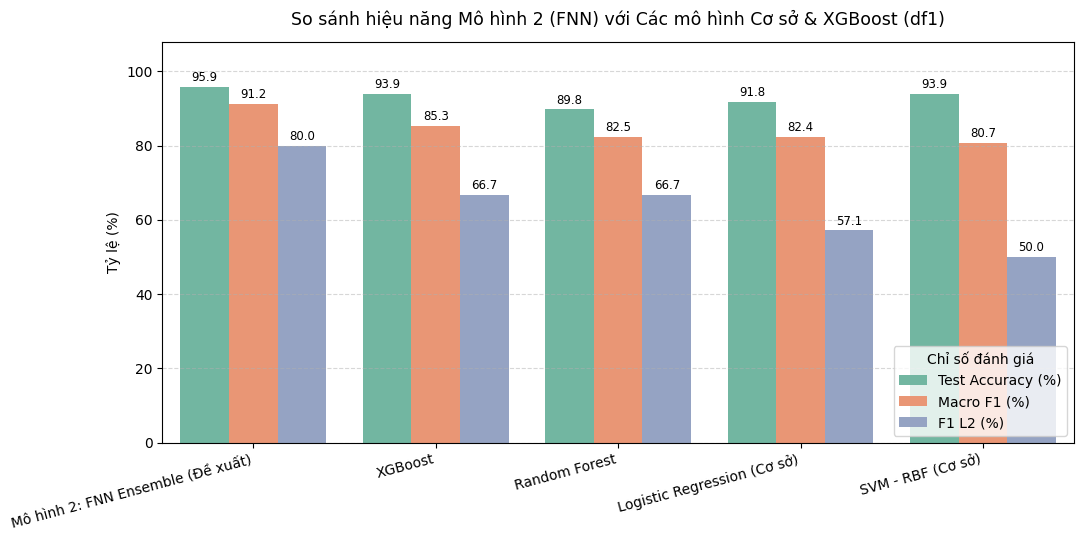

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# =========================================================================
# 0. KHỞI TẠO & CHIA TẬP DỮ LIỆU TRỰC TIẾP TỪ df1
# =========================================================================
if 'df1' not in globals():
    df1 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df1.columns]

X_original = df1[valid_features].copy()
Y = df1['Level'].copy()

valid_idx = Y.notna()
X_original = X_original[valid_idx].apply(pd.to_numeric, errors='coerce')
Y = Y[valid_idx]

if Y.dtype == 'object' or Y.dtype.name == 'category':
    mapped_Y = Y.map({'L0': 0, 'L1': 1, 'L2': 2})
    if mapped_Y.isna().any():
        le = LabelEncoder()
        Y = pd.Series(le.fit_transform(Y.astype(str)), index=Y.index)
    else:
        Y = mapped_Y.astype(int)
else:
    Y = Y.astype(int)
    if Y.min() == 1:
        Y = Y - 1

q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X_original.columns]
if len(q_cols) > 0:
    X_original['Q_mean'] = X_original[q_cols].mean(axis=1)
    X_original['Q_std'] = X_original[q_cols].std(axis=1)
    X_original['Q_max'] = X_original[q_cols].max(axis=1)

X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.15, random_state=42, stratify=Y
)

# =========================================================================
# 1. KHỞI TẠO CÁC MÔ HÌNH ĐỐI CHỨNG (CƠ SỞ + XGBOOST)
# =========================================================================
def get_baseline_models(seed):
    return {
        'Logistic Regression (Cơ sở)': LogisticRegression(
            max_iter=1000, random_state=seed
        ),
        'SVM - RBF (Cơ sở)': SVC(
            kernel='rbf', C=1.0, probability=True, random_state=seed
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=200, max_depth=6, random_state=seed
        ),
        'XGBoost': XGBClassifier(
            n_estimators=150,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric='mlogloss',
            random_state=seed
        )
    }

# =========================================================================
# 2. HUẤN LUYỆN 10-FOLD ENSEMBLE CHO TẤT CẢ MÔ HÌNH TRÊN df1
# =========================================================================
n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
output_classes = len(np.unique(Y_train_raw))

model_names = list(get_baseline_models(42).keys())
test_preds_dict = {name: np.zeros((len(X_test_raw), output_classes)) for name in model_names}
oof_preds_dict = {name: np.zeros((len(X_train_raw), output_classes)) for name in model_names}

print(f"🚀 Đang huấn luyện {n_splits}-Fold các mô hình cơ sở và XGBoost trên tập df1 ({len(df1)} mẫu)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_raw, Y_train_raw), 1):
    X_tr = X_train_raw.iloc[train_idx].copy()
    Y_tr = Y_train_raw.iloc[train_idx].copy()

    X_val = X_train_raw.iloc[val_idx].copy()
    Y_val = Y_train_raw.iloc[val_idx].copy()

    X_te = X_test_raw.copy()

    # Bước A: Điền khuyết bằng Median của tập Train Fold
    fold_medians = X_tr.median()
    X_tr = X_tr.fillna(fold_medians).fillna(0)
    X_val = X_val.fillna(fold_medians).fillna(0)
    X_te = X_te.fillna(fold_medians).fillna(0)

    # Bước B: Cắt ngoại lai IQR cho 'tg_sudung_dt'
    feature_outlier = 'tg_sudung_dt'
    if feature_outlier in X_tr.columns:
        Q1 = X_tr[feature_outlier].quantile(0.25)
        Q3 = X_tr[feature_outlier].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        X_tr[feature_outlier] = np.clip(X_tr[feature_outlier], lower_bound, upper_bound)
        X_val[feature_outlier] = np.clip(X_val[feature_outlier], lower_bound, upper_bound)
        X_te[feature_outlier] = np.clip(X_te[feature_outlier], lower_bound, upper_bound)

    # Bước C: Chuẩn hóa StandardScaler trên dữ liệu thật
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_val_scaled = scaler.transform(X_val)
    X_te_scaled = scaler.transform(X_te)

    # Bước D: Cân bằng lớp SMOTE chỉ trên tập Train
    sm = SMOTE(sampling_strategy='auto', random_state=42 + fold)
    X_tr_res, Y_tr_res = sm.fit_resample(X_tr_scaled, Y_tr)

    # Huấn luyện từng mô hình trong Fold hiện tại
    models = get_baseline_models(42 + fold)
    for name, clf in models.items():
        clf.fit(X_tr_res, Y_tr_res)
        oof_preds_dict[name][val_idx] = clf.predict_proba(X_val_scaled)
        test_preds_dict[name] += clf.predict_proba(X_te_scaled) / n_splits

print("✅ Hoàn tất huấn luyện tất cả mô hình đối chiếu trên df1!\n")

# Thêm kết quả của Mô hình 2 (FNN Ensemble trên df1) nếu đã chạy ở cell trước
if 'test_predictions_folds' in globals() and len(test_predictions_folds) == len(X_test_raw):
    test_preds_dict['Mô hình 2: FNN Ensemble (Đề xuất)'] = test_predictions_folds
    if 'oof_predictions' in globals() and len(oof_predictions) == len(X_train_raw):
        oof_preds_dict['Mô hình 2: FNN Ensemble (Đề xuất)'] = oof_predictions

# =========================================================================
# 3. TỔNG HỢP BẢNG SO SÁNH HIỆU NĂNG TOÀN DIỆN TRÊN df1
# =========================================================================
Y_true_test = Y_test_raw.values
Y_true_train = Y_train_raw.values
summary_rows = []

for name, pred_probs in test_preds_dict.items():
    y_pred = np.argmax(pred_probs, axis=1)
    f1_classes = f1_score(Y_true_test, y_pred, labels=[0, 1, 2], average=None, zero_division=0)

    oof_acc = (
        accuracy_score(Y_true_train, np.argmax(oof_preds_dict[name], axis=1)) * 100
        if name in oof_preds_dict else np.nan
    )

    summary_rows.append({
        'Mô hình': name,
        'OOF Val Acc (%)': round(oof_acc, 2),
        'Test Accuracy (%)': round(accuracy_score(Y_true_test, y_pred) * 100, 2),
        'Macro F1 (%)': round(f1_score(Y_true_test, y_pred, average='macro', zero_division=0) * 100, 2),
        'Weighted F1 (%)': round(f1_score(Y_true_test, y_pred, average='weighted', zero_division=0) * 100, 2),
        'F1 L0 (%)': round(f1_classes[0] * 100, 2),
        'F1 L1 (%)': round(f1_classes[1] * 100, 2),
        'F1 L2 (%)': round(f1_classes[2] * 100, 2),
    })

df_compare = pd.DataFrame(summary_rows).sort_values(by='Macro F1 (%)', ascending=False)

print("=" * 95)
print("📊 BẢNG SO SÁNH MÔ HÌNH 2 (FNN ENSEMBLE) VỚI CÁC MÔ HÌNH CƠ SỞ & XGBOOST TRÊN df1")
print("=" * 95)
print(df_compare.to_string(index=False))
print("=" * 95)

# =========================================================================
# 4. VẼ BIỂU ĐỒ CỘT SO SÁNH TRỰC QUAN
# =========================================================================
df_melt = df_compare.melt(
    id_vars='Mô hình',
    value_vars=['Test Accuracy (%)', 'Macro F1 (%)', 'F1 L2 (%)'],
    var_name='Chỉ số',
    value_name='Điểm số (%)'
)

plt.figure(figsize=(11, 5.5))
ax = sns.barplot(data=df_melt, x='Mô hình', y='Điểm số (%)', hue='Chỉ số', palette='Set2')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', fontsize=8.5, padding=2)

plt.title('So sánh hiệu năng Mô hình 2 (FNN) với Các mô hình Cơ sở & XGBoost (df1)', fontsize=12.5, pad=12)
plt.ylabel('Tỷ lệ (%)')
plt.xlabel('')
plt.ylim(0, 108)
plt.xticks(rotation=15, ha='right')
plt.legend(title='Chỉ số đánh giá', loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()